In [236]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from kneed import KneeLocator
import seaborn as sns

In [252]:
bowlingStats=pd.read_csv("BowlingStatsKmeans.csv")
bowlingStats=bowlingStats[bowlingStats.Year==2021]
bowlingStatistics=bowlingStats.copy()
bowlingStats[1:]

,POS,Player,Mat,Inns,Ov,Runs,Wkts,BBI,Avg,Econ,SR,4w,5w,Year
1,2,Avesh Khan,16,16,61.0,450,24,3/13,18.75,7.37,15.25,0,0,2021
2,3,Jasprit Bumrah,14,14,55.0,410,21,3/36,19.52,7.45,15.71,0,0,2021
3,4,Shardul Thakur,16,16,59.5,527,21,3/28,25.09,8.80,17.09,0,0,2021
4,5,Mohammad Shami,14,14,52.4,395,19,3/21,20.78,7.50,16.63,0,0,2021
5,6,Varun Chakaravarthy,17,17,68.0,448,18,3/13,24.88,6.58,22.66,0,0,2021
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,106,Ben Stokes,1,1,1.0,12,0,0/12,0.00,12.00,0.00,0,0,2021
106,107,Dhawal Kulkarni,1,1,4.0,48,0,0/48,0.00,12.00,0.00,0,0,2021
107,108,Shreyas Gopal,3,3,7.0,84,0,0/9,0.00,12.00,0.00,0,0,2021
108,109,Kamlesh Nagarkoti,1,1,2.0,25,0,0/25,0.00,12.50,0.00,0,0,2021


In [239]:
bowlingStats = bowlingStats.drop(columns=['POS', 'Year','BBI'])
bowlingStats

,Player,Mat,Inns,Ov,Runs,Wkts,Avg,Econ,SR,4w,5w
0,Harshal Patel,15,15,56.2,459,32,14.34,8.14,10.56,1,1
1,Avesh Khan,16,16,61.0,450,24,18.75,7.37,15.25,0,0
2,Jasprit Bumrah,14,14,55.0,410,21,19.52,7.45,15.71,0,0
3,Shardul Thakur,16,16,59.5,527,21,25.09,8.80,17.09,0,0
4,Mohammad Shami,14,14,52.4,395,19,20.78,7.50,16.63,0,0
...,...,...,...,...,...,...,...,...,...,...,...
105,Ben Stokes,1,1,1.0,12,0,0.00,12.00,0.00,0,0
106,Dhawal Kulkarni,1,1,4.0,48,0,0.00,12.00,0.00,0,0
107,Shreyas Gopal,3,3,7.0,84,0,0.00,12.00,0.00,0,0
108,Kamlesh Nagarkoti,1,1,2.0,25,0,0.00,12.50,0.00,0,0


In [240]:
bowlingStats=bowlingStats[(bowlingStats['Ov'] > 3.0) & (bowlingStats['Mat']>3)].to_numpy()
bowlingStats

array([['Harshal Patel', 15, 15, 56.2, 459, 32, 14.34, 8.14, 10.56, 1, 1],
       ['Avesh Khan', 16, 16, 61.0, 450, 24, 18.75, 7.37, 15.25, 0, 0],
       ['Jasprit Bumrah', 14, 14, 55.0, 410, 21, 19.52, 7.45, 15.71, 0,
        0],
       ['Shardul Thakur', 16, 16, 59.5, 527, 21, 25.09, 8.8, 17.09, 0, 0],
       ['Mohammad Shami', 14, 14, 52.4, 395, 19, 20.78, 7.5, 16.63, 0, 0],
       ['Varun Chakaravarthy', 17, 17, 68.0, 448, 18, 24.88, 6.58, 22.66,
        0, 0],
       ['Rashid Khan', 14, 14, 56.0, 375, 18, 20.83, 6.69, 18.66, 0, 0],
       ['Yuzvendra Chahal', 15, 15, 53.0, 374, 18, 20.77, 7.05, 17.66, 0,
        0],
       ['Arshdeep Singh', 12, 12, 41.2, 342, 18, 19.0, 8.27, 13.77, 0, 1],
       ['Sunil Narine', 14, 14, 56.0, 361, 16, 22.56, 6.44, 21.0, 1, 0],
       ['Jason Holder', 8, 8, 31.5, 247, 16, 15.43, 7.75, 11.93, 1, 0],
       ['Axar Patel', 12, 12, 46.0, 306, 15, 20.4, 6.65, 18.4, 0, 0],
       ['Kagiso Rabada', 15, 15, 56.0, 456, 15, 30.4, 8.14, 22.4, 0, 0],
       [

In [241]:
bowlingStatsNoLabel=bowlingStats[:,1:]
bowlingStatsNoLabel
scaler = StandardScaler()
scaled_features = scaler.fit_transform(bowlingStatsNoLabel)
scaled_features

array([[ 1.29777137,  1.4588643 ,  1.4975512 ,  1.68112161,  3.46378433,
        -1.0191365 ,  0.18432191, -1.13778485,  2.16756177,  4.65474668],
       [ 1.56041557,  1.7081175 ,  1.77677016,  1.61266875,  2.2520167 ,
        -0.75662939, -0.43275579, -0.72715844, -0.37371755, -0.21483446],
       [ 1.03512716,  1.20961111,  1.42774646,  1.30843384,  1.79760383,
        -0.71079481, -0.36864382, -0.68688378, -0.37371755, -0.21483446],
       [ 1.56041557,  1.7081175 ,  1.68951424,  2.19832096,  1.79760383,
        -0.37923821,  0.71324566, -0.56605981, -0.37371755, -0.21483446],
       [ 1.03512716,  1.20961111,  1.27650286,  1.19434574,  1.49466192,
        -0.63579278, -0.32857384, -0.60633447, -0.37371755, -0.21483446],
       [ 1.82305978,  1.9573707 ,  2.18396448,  1.597457  ,  1.34319097,
        -0.39173855, -1.06586149, -0.07838623, -0.37371755, -0.21483446],
       [ 1.03512716,  1.20961111,  1.48591708,  1.04222828,  1.34319097,
        -0.63281651, -0.97770753, -0.42860065

In [242]:
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(scaled_features)
principalComponents.shape

(68, 2)

In [243]:
silhouette_coefficients = []
kmeans_kwargs = {"init": "random","n_init": 10,"max_iter": 500,"random_state":40}
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(scaled_features)
    score = silhouette_score(scaled_features, kmeans.labels_)
    silhouette_coefficients.append(score)


In [244]:
silhouette_coefficients

[0.31621569745263284,
 0.2628997480154246,
 0.2838473941881269,
 0.2538807533225951,
 0.2877006976084604,
 0.2715847516557974,
 0.2951735393781645,
 0.28565761446772087,
 0.2684538498674077]

In [245]:
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(scaled_features)
    sse.append(kmeans.inertia_)
sse

[680.0000000000001,
 444.3235081825971,
 355.8886147451047,
 288.81983594040946,
 252.5678503854796,
 210.7741451557905,
 192.84847733135445,
 177.0132406239743,
 158.08521136691576,
 151.20290521022537]

In [246]:
kl = KneeLocator(range(1, 11), sse, curve="convex", direction="decreasing" )
kl.elbow

4

In [247]:
kmeans = KMeans(n_clusters=4, **kmeans_kwargs)
kmeans.fit(scaled_features)
labels=kmeans.labels_
labels

array([3, 2, 2, 2, 2, 2, 2, 2, 3, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2,
       0, 0, 2, 2, 0, 0, 3, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 0])

In [227]:
df1 = pd.DataFrame({'Component1':principalComponents[:,0], 'Component2':principalComponents[:,1],"Cluster_Kmeans":labels,'Player':bowlingStats[:,0]})
df1

,Component1,Component2,Cluster_Kmeans,Player
0,5.250361,1.259296,3,Harshal Patel
1,4.004235,-0.232030,2,Avesh Khan
2,3.092362,-0.004532,2,Jasprit Bumrah
3,3.818745,-1.029359,2,Shardul Thakur
4,2.813382,-0.076514,2,Mohammad Shami
...,...,...,...,...
63,-3.388779,-0.287803,1,Mahipal Lomror
64,-4.272991,-3.484240,1,Fabian Allen
65,-2.980448,-2.656534,1,Riyan Parag
66,-2.292117,3.863001,0,Aiden Markram


In [265]:
processedBowlingStats=bowlingStatistics.copy()
processedBowlingStats=pd.merge(processedBowlingStats,df1,on="Player",how="left").dropna()
processedBowlingStats["Cluster_Kmeans"] = processedBowlingStats["Cluster_Kmeans"].astype(int)
processedBowlingStats.columns
for i in range(0,3):
    print("Cluster Number ", i)
    temp=processedBowlingStats[processedBowlingStats["Cluster_Kmeans"] == i]
    display(temp)

Cluster Number  0


,POS,Player,Mat,Inns,Ov,Runs,Wkts,BBI,Avg,Econ,SR,4w,5w,Year,Component1,Component2,Cluster_Kmeans
10,11,Jason Holder,8,8,31.5,247,16,4/52,15.43,7.75,11.93,1,0,2021,0.840168,1.730892,0
20,21,Lockie Ferguson,8,8,30.0,224,13,3/18,17.23,7.46,13.84,0,0,2021,0.157536,1.250611,0
22,23,Anrich Nortje,8,8,30.2,187,12,2/12,15.58,6.16,15.16,0,0,2021,0.058885,1.598087,0
23,24,Ravi Bishnoi,9,9,35.0,222,12,3/24,18.50,6.34,17.50,0,0,2021,0.413251,1.125799,0
26,27,Shivam Mavi,9,9,32.1,233,11,4/21,21.18,7.24,17.54,1,0,2021,0.557899,1.228195,0
27,28,Josh Hazlewood,9,9,35.0,293,11,3/24,26.63,8.37,19.09,0,0,2021,0.321515,0.147502,0
29,30,Pat Cummins,7,7,26.5,237,9,3/24,26.33,8.83,17.88,0,0,2021,-0.622952,0.469413,0
30,31,Kyle Jamieson,9,9,28.0,269,9,3/41,29.88,9.60,18.66,0,0,2021,-0.174692,-0.147074,0
31,32,Sam Curran,9,9,33.0,328,9,3/34,36.44,9.93,22.00,0,0,2021,-0.014729,-0.779468,0
33,34,Nathan Coulter-Nile,5,5,20.0,127,7,4/14,18.14,6.35,17.14,1,0,2021,-1.076302,2.224638,0


Cluster Number  1


,POS,Player,Mat,Inns,Ov,Runs,Wkts,BBI,Avg,Econ,SR,4w,5w,Year,Component1,Component2,Cluster_Kmeans
39,40,Bhuvneshwar Kumar,11,11,42.0,335,6,1/16,55.83,7.97,42.0,0,0,2021,0.007403,-2.373707,1
44,45,Krunal Pandya,13,12,33.1,265,5,1/13,53.00,7.98,39.8,0,0,2021,-0.132910,-2.116012,1
45,46,Khaleel Ahmed,7,7,27.0,219,5,3/21,43.80,8.11,32.4,0,0,2021,-1.338843,-0.750496,1
49,50,Shakib Al Hasan,8,8,26.0,187,4,1/1,46.75,7.19,39.0,0,0,2021,-1.413498,-1.026045,1
51,52,Jaydev Unadkat,6,6,22.0,168,4,3/15,42.00,7.63,33.0,0,0,2021,-1.858791,-0.379566,1
55,56,Dan Christian,9,9,16.4,155,4,2/14,38.75,9.30,25.0,0,0,2021,-1.357208,-0.467446,1
56,57,Riley Meredith,5,5,17.0,169,4,1/29,42.25,9.94,25.5,0,0,2021,-2.213864,-0.400090,1
57,58,Washington Sundar,6,6,16.0,118,3,1/7,39.33,7.37,32.0,0,0,2021,-2.171318,-0.038407,1
60,61,Glenn Maxwell,15,6,16.0,135,3,2/23,45.00,8.43,32.0,0,0,2021,-1.362635,-0.957994,1
61,62,Sandeep Sharma,7,7,23.3,203,3,1/20,67.66,8.63,47.0,0,0,2021,-2.181498,-2.443022,1


Cluster Number  2


,POS,Player,Mat,Inns,Ov,Runs,Wkts,BBI,Avg,Econ,SR,4w,5w,Year,Component1,Component2,Cluster_Kmeans
1,2,Avesh Khan,16,16,61.0,450,24,3/13,18.75,7.37,15.25,0,0,2021,4.004235,-0.232030,2
2,3,Jasprit Bumrah,14,14,55.0,410,21,3/36,19.52,7.45,15.71,0,0,2021,3.092362,-0.004532,2
3,4,Shardul Thakur,16,16,59.5,527,21,3/28,25.09,8.80,17.09,0,0,2021,3.818745,-1.029359,2
4,5,Mohammad Shami,14,14,52.4,395,19,3/21,20.78,7.50,16.63,0,0,2021,2.813382,-0.076514,2
5,6,Varun Chakaravarthy,17,17,68.0,448,18,3/13,24.88,6.58,22.66,0,0,2021,3.840028,-0.865969,2
6,7,Rashid Khan,14,14,56.0,375,18,3/36,20.83,6.69,18.66,0,0,2021,2.791614,-0.003417,2
7,8,Yuzvendra Chahal,15,15,53.0,374,18,3/11,20.77,7.05,17.66,0,0,2021,2.913293,-0.103340,2
9,10,Sunil Narine,14,14,56.0,361,16,4/21,22.56,6.44,21.00,1,0,2021,2.910080,0.289533,2
11,12,Axar Patel,12,12,46.0,306,15,3/21,20.40,6.65,18.40,0,0,2021,1.719490,0.419315,2
12,13,Kagiso Rabada,15,15,56.0,456,15,3/36,30.40,8.14,22.40,0,0,2021,2.790992,-1.141321,2


c:\users\rajee\appdata\local\programs\python\python38\lib\site-packages\seaborn\regression.py:581: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


<Figure size 1440x1440 with 0 Axes>

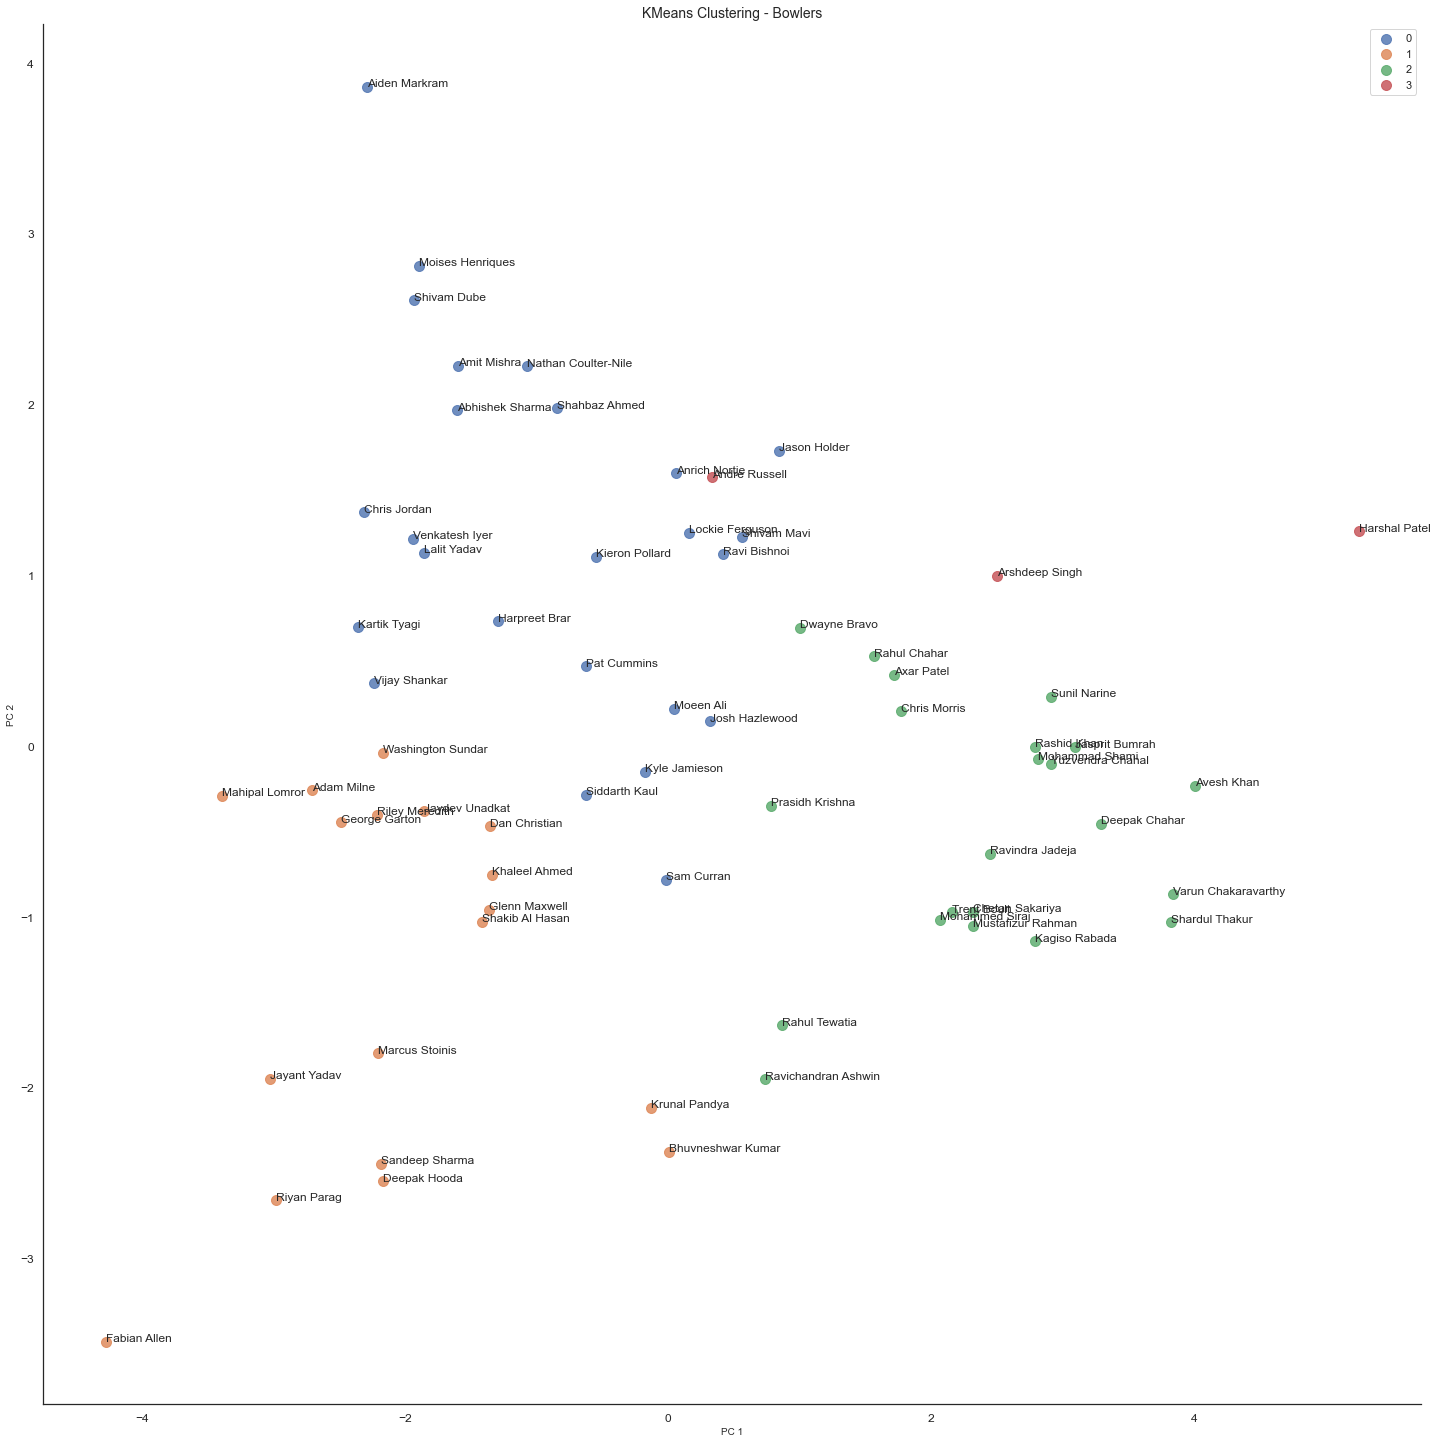

In [214]:
sns.set(style="white")
plt.figure(figsize=(20,20))
ax = sns.lmplot(x="Component1", y="Component2", hue='Cluster_Kmeans', data = df1, legend=False,
fit_reg=False, size = 20, scatter_kws={"s": 100})
texts = []
for x, y, s in zip(df1.Component1, df1.Component2,df1.Player):
    texts.append(plt.text(x, y, s))
#ax.set(ylim=(2, 2))
plt.tick_params(labelsize=12)
plt.title("KMeans Clustering - Bowlers",fontsize = 14 ) #title
plt.xlabel("PC 1", fontsize = 10)
plt.ylabel("PC 2", fontsize = 10)
plt.legend()
plt.show()